# Lab: MLP Forward Propagation

**BINF 6210/8210 - Machine Learning for Bioinformatics**
___

**Learning objectives:**
- Calculate affine transformations and activations
- Ceason about derivatives and saturation
- Implement a complete forward pass with matrix multiplication
- Explore nonlinear biological relationships.

**Sections:**
- One artificial neuron
- Activation functions and their derivatives
- Vectorized forward propagation

We use the lecture convention $z^{(l)}=W^{(l)}a^{(l-1)}+b^{(l)}$ and $a^{(l)}=g^{(l)}(z^{(l)})$. In code, **samples are rows**, so the batch operation is `A @ W.T + b`. This is the transpose of the lecture's column-vector notation.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)
SEED = 42

## 1. One artificial neuron
For two standardized biological measurements $x_1,x_2$, calculate $z=w_1x_1+w_2x_2+b$ and then apply the sigmoid. Predict the result by hand first.

In [3]:
x = np.array([1.2, -0.5])
w = np.array([0.8, -1.1])
b = 0.3
z = x @ w + b
sigmoid = lambda z: 1 / (1 + np.exp(-np.clip(z, -500, 500)))
print('z =', z, ', sigmoid(z) =', round(sigmoid(z), 1))
assert np.isclose(z, 1.81)

z = 1.81 , sigmoid(z) = 0.9


## 2. Activation functions and their derivatives
Plot sigmoid, tanh, ReLU, and their derivatives. The derivative of ReLU at zero is conventionally set to zero in this lab. Discuss saturation and dying ReLU.

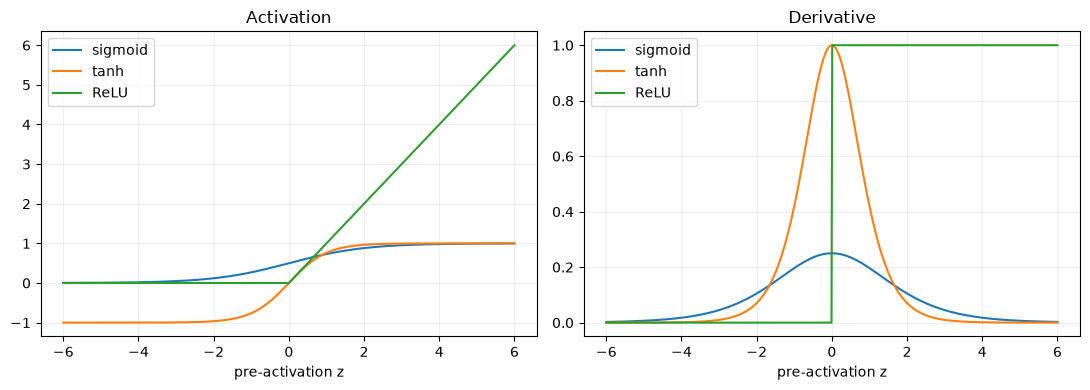

In [4]:
# range of z
zgrid = np.linspace(-6,6,600)

# three activation functions
functions = {'sigmoid': (sigmoid(zgrid), sigmoid(zgrid)*(1-sigmoid(zgrid))),
             'tanh': (np.tanh(zgrid), 1-np.tanh(zgrid)**2),
             'ReLU': (np.maximum(zgrid,0), (zgrid>0).astype(float))}

# plot the activation functions and their derivatives
fig, axes = plt.subplots(1,2,figsize=(11,4))
for name,(a,d) in functions.items():
    axes[0].plot(zgrid,a,label=name); axes[1].plot(zgrid,d,label=name)
for ax,title in zip(axes,['Activation','Derivative']):
    ax.set_title(title); ax.set_xlabel('pre-activation z'); ax.grid(alpha=.2); ax.legend()
plt.tight_layout()

**Exercise 1:** At $z=5$, compare the sigmoid and ReLU derivatives. Why can saturated sigmoid units learn slowly? What is the drawback of ReLU at negative $z$?

## 3. Vectorized forward propagation
Architecture: 3 biological features → 4 ReLU hidden units → 1 sigmoid output. `W1` is `(4,3)` and `W2` is `(1,4)`. Compute both layers by hand for the first sample, then compare with NumPy.

In [17]:
X = np.array([[0.5, -1.0, 1.2], [1.0, 0.3, -0.4]])
print('Given X:')
print(X)
print()

W1 = np.array([[.2,-.4,.5],[-.1,.6,.2],[.7,.1,-.3],[.2,.2,.2]])
print('Given W1:')
print(W1)
print()

b1 = np.array([.1,0.,-.2,.05])
print('Given b1:')
print(b1)
print()

W2 = np.array([[.5,-.2,.4,.3]])
print('Given W2:')
print(W2)
print()

b2 = np.array([-.1])
print('Given b2:')
print(b2)
print()

# compute Z1
Z1 = X @ W1.T + b1

A1 = np.maximum(Z1,0)

Z2 = A1 @ W2.T + b2

Yhat = sigmoid(Z2)
for name,arr in [('Z1',Z1),('A1',A1),('Z2',Z2),('Yhat',Yhat)]: print(name, '\n shape:', arr.shape,'\n',arr, '\n')
assert Yhat.shape == (2,1)

Given X:
[[ 0.5 -1.   1.2]
 [ 1.   0.3 -0.4]]

Given W1:
[[ 0.2 -0.4  0.5]
 [-0.1  0.6  0.2]
 [ 0.7  0.1 -0.3]
 [ 0.2  0.2  0.2]]

Given b1:
[ 0.1   0.   -0.2   0.05]

Given W2:
[[ 0.5 -0.2  0.4  0.3]]

Given b2:
[-0.1]

Z1 
 shape: (2, 4) 
 [[ 1.2  -0.41 -0.31  0.19]
 [-0.02 -0.    0.65  0.23]] 

A1 
 shape: (2, 4) 
 [[1.2  0.   0.   0.19]
 [0.   0.   0.65 0.23]] 

Z2 
 shape: (2, 1) 
 [[0.557]
 [0.229]] 

Yhat 
 shape: (2, 1) 
 [[0.6358]
 [0.557 ]] 



**Exercise 2:** Change `b1[0]` and explain which hidden activations and output predictions change. Why is a bias not counted in fan-in?

## 4. A nonlinear biological response (synthetic demonstration)
Simulate a disease-risk pattern in which two standardized metabolite measurements interact nonlinearly. This is **synthetic**, not a measured clinical relationship. Compare logistic regression with an MLP using a train/test split and training-only standardization.

Simulate a scenario: disease risk might increase substantially only when both glucose and triglyceride concentrations exceed certain thresholds.

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score

rng = np.random.default_rng(SEED)

Xbio = rng.normal(size=(1200,2))

logit = -1.2 + 2.8*(Xbio[:,0]>0.6)*(Xbio[:,1]>0.6) + .3*Xbio[:,0]

p = sigmoid(logit)

ybio = rng.binomial(1,p)

Xt,Xs,yt,ys = train_test_split(Xbio, ybio, test_size=.25, stratify=ybio, random_state=SEED)

models = {'Logistic regression':make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000)),
          'MLP':make_pipeline(StandardScaler(),MLPClassifier(hidden_layer_sizes=(12,8),max_iter=600,early_stopping=True,random_state=SEED))}

for name,model in models.items():
    model.fit(Xt,yt)
    print(name,'test ROC AUC:',round(roc_auc_score(ys,model.predict_proba(Xs)[:,1]),3))

Logistic regression test ROC AUC: 0.611
MLP test ROC AUC: 0.6


**Exit questions:** Distinguish pre-activation from activation; give the shapes of the two weight matrices; explain what nonlinear hidden layers add beyond logistic regression.